# Finish the fine-tuned model served behind an API

A coworking-space chain in Tashkent and Seoul routes member messages (Uzbek, Russian, Korean) to one of three teams:
Billing, Facilities or Events. You will score the untuned model and the prompted model on the 40 held-out messages,
train the LoRA adapter, test whether the tuned model really beats the prompted one, and then serve it behind FastAPI
and check that the endpoint gives the same answers as your evaluation.

About 5 minutes on a free Colab CPU runtime. No GPU, account or key is needed. Run the cells from top to bottom.

**One difference from the lesson.** The lesson's numbers come from MLX on a Mac (300 steps, adapters on all 30
layers), and MLX does not run on Colab, so this notebook trains the same kind of adapter with PyTorch and PEFT on
the CPU for only 100 steps on the top 16 layers: its tuned model gets fewer messages right than the lesson's (25 of 40
in our run instead of 37), and that changes one verdict, as step 9 shows.

## 1. Install the library versions we used

Colab already has PyTorch and Transformers. This cell pins Transformers, installs PEFT (the Hugging Face library
that adds LoRA adapters to a model), and pins FastAPI and httpx, which the test client needs. It prints nothing, or
only a note about restarting, when it works. You do not need to restart.

In [1]:
%pip install -q transformers==5.22.2 peft==0.21.3 fastapi==0.162.7 httpx==0.28.1

Note: you may need to restart the kernel to use updated packages.


## 2. The data

The same rows as the lesson. A hosted model wrote the messages, one team at a time, so each message's team is its
label. `TRAIN` teaches the adapter, `VALID` is checked during training, and `HELD` is the held-out set: neither
model ever trains on it, so it is the fair test for both. `HOSTED` and `HOSTED_RULES` are the recorded answers of
the prompted hosted model from the lesson (google/gemini-2.5-flash-lite, temperature 0, recorded 2026-11-14). You
have no key, so the notebook uses those recorded answers as data.

**Look for:** 248 training rows, 21 validation rows, 40 held-out rows (14 Billing, 13 Facilities, 13 Events), and
the hosted model right on 40 of 40 with both prompts.

In [2]:
SYSTEM = ("You route member messages for a coworking-space chain. "
          "Reply with one team name only: Billing, Facilities or Events.")
TEAMS = ["Billing", "Facilities", "Events"]

# (message, team): the rows the adapter learns from
TRAIN = [
    ("Во время митапа было слишком жарко, кондиционер не справился.", "Facilities"),
    ("Кто-нибудь может поделиться презентацией с вчерашнего выступления?", "Events"),
    ("Wi-Fi работает очень медленно, пожалуйста, проверьте.", "Facilities"),
    ("인터넷이 너무 느려서 일을 못 하겠어요.", "Facilities"),
    ("회의실 예약 건으로 인보이스 발급 부탁드립니다. 타슈켄트 지점.", "Billing"),
    ("혹시 이 이벤트 링크 공유해주실 수 있나요?", "Events"),
    ("Здравствуйте. Я не смогу прийти на нетворкинг. Как отменить запись?", "Events"),
    ("발표회장에서 프로젝터가 안 켜져요.", "Facilities"),
    ("다음 주에 네트워킹 저녁 모임을 열면 어떨까요? 누구 참여하실래요?", "Events"),
    ("Пожалуйста, проверьте скорость Wi-Fi. У меня онлайн-встреча.", "Facilities"),
    ("밋업 티켓이 두 번 결제된 것 같아요!", "Billing"),
    ("Нам очень понравился сегодняшний митап. Спасибо организаторам!", "Events"),
    ("안녕하세요, 에어컨이 작동하지 않아요. 너무 더워요.", "Facilities"),
    ("취소된 밋업 참가비 환불은 언제 받을 수 있나요?", "Billing"),
    ("제 월간 이용권에 할인이 있나요?", "Billing"),
    ("소음이 좀 심한데, 줄여주시겠어요?", "Facilities"),
    ("Depozitni qaytarish haqida ma'lumot kerak edi.", "Billing"),
    ("Кухня грязная, кто-нибудь уберет?", "Facilities"),
    ("Mening kartamdan pul o'tkazishda muammo bo'ldi. Yordam bera olasizmi?", "Billing"),
    ("Assalomu alaykum! Bu hafta qanday tadbirlar bor?", "Events"),
    ("이 이벤트 티켓 비용을 환불받을 수 있나요? 실수로 두 번 결제했습니다.", "Billing"),
    ("Mening to'lovim o'tmayapti, xatolik bo'lyapti. Yordam bering, men uchrashuvga kechikayapman.", "Billing"),
    ("Assalomu alaykum, hisobimda nima uchun ikki marta pul yechilganini tushuntirib bera olasizmi?", "Billing"),
    ("Kechirasiz, men tarmoq tadbiriga bora olmasam kerak. Qanday bekor qilishim mumkin?", "Events"),
    ("Отличная идея! Может, организуем нетворкинг-вечер в пятницу?", "Events"),
    ("Хочу вернуть деньги за воркшоп, так как не смогу прийти. Как это сделать?", "Billing"),
    ("회의실 테이블에 흠집이 났어요.", "Facilities"),
    ("이번 행사 정말 좋았습니다! 혹시 발표 자료 공유 가능하신가요?", "Events"),
    ("Workshop uchun to'lovim qachon amalga oshadi?", "Billing"),
    ("Привет! Какие мероприятия планируются на этой неделе?", "Events"),
    ("워크숍 티켓 환불 요청합니다. 참석 못 해요.", "Billing"),
    ("Mening oxirgi oylik to'lovimga chegirma bormi?", "Billing"),
    ("이 네트워킹 저녁은 어디서 열리나요?", "Events"),
    ("오늘 강연은 어디에서 열리나요?", "Events"),
    ("지난주 이벤트 참가비를 납부했는데, 영수증이 안 보여요.", "Billing"),
    ("Освещение в переговорке мерцает.", "Facilities"),
    ("Моя карта доступа не работает, можете помочь?", "Facilities"),
    ("Стол сломан, сидеть невозможно.", "Facilities"),
    ("Kimdir menga bu tadbirga kirish uchun havola yubora oladimi, iltimos?", "Events"),
    ("안녕하세요, 이 책상이 부서진 것 같고 교체해야 합니다.", "Facilities"),
    ("На кухне сломалась кофемашина.", "Facilities"),
    ("Я записался на тренинг, но теперь не смогу прийти.", "Events"),
    ("Оплата за мастер-класс не прошла. В чем проблема?", "Billing"),
    ("Salom, konditsioner ishlamayapti, juda issiq bo'lyapti.", "Facilities"),
    ("어제 강연 자료 슬라이드 공유해 주실 분 있나요?", "Events"),
    ("Bu workshopga to'lov qancha bo'ladi?", "Billing"),
    ("Men mart oyida texnologiya haqida ma'ruza o'qishni taklif qilmoqchiman.", "Events"),
    ("Какие у вас есть идеи для новых ивентов?", "Events"),
    ("오늘 청소 안 했나요? 문 손잡이가 끈적해요.", "Facilities"),
    ("Привет, есть ли проектор для сегодняшнего мероприятия?", "Facilities"),
    ("무료 이벤트에 신청했는데 참석이 어려울 것 같습니다. 어떻게 취소하나요?", "Events"),
    ("리셉션 프린터에 종이가 걸렸어요.", "Facilities"),
    ("Пришлите, пожалуйста, счет-фактуру для бронирования переговорной. Сеул.", "Billing"),
    ("Tashkent ofisiga mentordan qanday hisob-faktura olish mumkin?", "Billing"),
    ("Всем привет! Какие мероприятия запланированы на эту неделю?", "Events"),
    ("Как мне оплатить этот воркшоп?", "Billing"),
    ("Xabaringiz uchun tashakkur! Yana shunday qiziqarli tadbirlarni kutib qolamiz.", "Events"),
    ("Здравствуйте, не могли бы вы объяснить, почему с моей карты дважды списали оплату за коворкинг?", "Billing"),
    ("Konferensiya zalida ekran ko'rinmayapti.", "Facilities"),
    ("오늘 저희는 워크숍을 가졌는데 장소가 너무 더웠습니다.", "Facilities"),
    ("이번 달 요금이 왜 이렇게 많이 나왔죠?", "Billing"),
    ("정보 감사합니다! 다음 행사도 기대하겠습니다.", "Events"),
    ("Ключ от кабинета потерялся, помогите открыть.", "Facilities"),
    ("좋은 생각이네요! 새로운 이벤트 아이디어 더 있나요?", "Events"),
    ("미팅룸 비용이 예상보다 많이 나왔어요. 왜죠?", "Billing"),
    ("행사장에 너무 시끄럽습니다. 제발 조용히 해주세요!", "Facilities"),
    ("타슈켄트 사무실의 화장실 청소가 필요합니다.", "Facilities"),
    ("보증금을 환불받아야 합니다. 언제 돈이 입금될까요?", "Billing"),
    ("Почему с меня списали дважды за воркшоп?", "Billing"),
    ("Спасибо за информацию! Очень жду предстоящие события.", "Events"),
    ("Stul buzilgan, o'tirishning iloji yo'q.", "Facilities"),
    ("Assalomu alaykum. Sizlar bilan hamkorlik qilishdan xursandman!", "Events"),
    ("이벤트 홀이 너무 시끄러워요. 음악 소리가 너무 커요.", "Facilities"),
    ("Salom, 2-qavatdagi kichik xonada Wi-Fi ishlmayapti.", "Facilities"),
    ("제 전자 출입 카드가 작동하지 않아 들어갈 수가 없어요. 어떻게 해야 하나요?", "Facilities"),
    ("새로운 회원들을 위한 사물함이 충분하지 않은 것 같아요.", "Facilities"),
    ("Какая стоимость аренды переговорной комнаты на 3 часа?", "Billing"),
    ("Проектор в зале для мероприятий не работает, презентация прервалась.", "Facilities"),
    ("밋업 중에 홀이 너무 더워졌어요. 환풍기 틀어주세요.", "Facilities"),
    ("다음 달에 기술 관련 강연을 하고 싶습니다. 제안해도 될까요?", "Events"),
    ("Можно ли вернуть деньги за это мероприятие? Я случайно оплатил дважды.", "Billing"),
    ("Uchrashuvga qanday ro'yxatdan o'tishim mumkin? Bu bepulmi?", "Events"),
    ("프린터가 또 고장났어요. 언제 고쳐지나요?", "Facilities"),
    ("Почему оплата в этом месяце выше, чем обычно?", "Billing"),
    ("Kimdir kechagi prezentatsiyaning slaydlarini bo'lishishi mumkinmi?", "Events"),
    ("Men aprel oyi uchun hisob-faktura ololmadim.", "Billing"),
    ("Мне нужно отменить запись на мероприятие. Извините!", "Events"),
    ("안녕하세요, 과정 비용은 어떻게 지불하나요? 가격이 궁금합니다.", "Billing"),
    ("이번 달 멤버십 요금이 얼마인가요?", "Billing"),
    ("Loker kaliti yo'qoldi, ochib bera olasizmi?", "Facilities"),
    ("Здравствуйте, возникла проблема с оплатой за прошлый месяц, можете проверить?", "Billing"),
    ("Kecha bo'lib o'tgan tadbirdan ma'ruzachi slaydlarini kimdir yubora oladimi?", "Events"),
    ("와이파이가 너무 느려요. 확인 부탁드립니다.", "Facilities"),
    ("어제 발표 자료 공유해주실 분 계신가요?", "Events"),
    ("Какие у вас новые тарифы? Они точно изменились?", "Billing"),
    ("Мне нужен чек об оплате за мартовский пакет.", "Billing"),
    ("Nima uchun tadbir boshlanishidan oldin menga xabar bermadilar? Kech qoldim!", "Events"),
    ("Здравствуйте. Буду рад сотрудничеству!", "Events"),
    ("Я хочу вернуть деньги за пропущенный митап.", "Billing"),
    ("새로운 이벤트 아이디어가 있으신가요?", "Events"),
    ("결제 오류가 발생했습니다. 카드에서 이중으로 청구되었어요.", "Billing"),
    ("Не работает отопление, в офисе холодно.", "Facilities"),
    ("이 세미나는 몇 시에 시작하나요?", "Events"),
    ("В принтере закончилась бумага.", "Facilities"),
    ("프린터에서 빈 페이지만 나와요.", "Facilities"),
    ("신용카드 결제가 자꾸 실패해요. 도와주세요.", "Billing"),
    ("Bunaqa kechki tadbirlar ko'proq bo'lsin iltimos!", "Events"),
    ("Mening o'tgan oygi to'lovim qabul qilinmagan. Kartamda yetarli mablag' bor edi. Nima bo'ldi?", "Billing"),
    ("Где пройдет этот вечер нетворкинга?", "Events"),
    ("Ташкент, 3 этаж. Кондиционер не дует.", "Facilities"),
    ("Туалет в ташкентском офисе нуждается в уборке.", "Facilities"),
    ("Когда начинаются мероприятия в Ташкенте?", "Events"),
    ("이번 주 이벤트는 무엇인가요? 어디서 확인할 수 있나요?", "Events"),
    ("Zudlik bilan! Tadbir zalida mikrofon ovozi chiqmayapti!", "Facilities"),
    ("Yig'ilish zalida proyektor ishlamayapti, tadbir boshlanishi kerak edi.", "Facilities"),
    ("다음 주에 소규모 밋업을 제안하고 싶습니다. 주제: 신기술.", "Events"),
    ("Men depozitni qaytarib olishim kerak. Qachon pul tushadi?", "Billing"),
    ("Всем привет! Какие мероприятия на этой неделе?", "Events"),
    ("Проблема с доступом, дверь не открывается.", "Facilities"),
    ("이 책상이 부서진 것 같아요. 문이 열려 있었어요.", "Facilities"),
    ("안녕하세요! 이번 주에 어떤 이벤트가 있나요?", "Events"),
    ("Кто-нибудь знает, где найти запись вчерашней лекции?", "Events"),
    ("Salom! Bu hafta qanday tadbirlar bor?", "Events"),
    ("Есть ли скидка на мой месячный абонемент?", "Billing"),
    ("Salom, mening oy avvalgi to'lovimda muammo bor, siz tekshira olasizmi?", "Billing"),
    ("난방이 안 돼요. 사무실이 추워요.", "Facilities"),
    ("Я опоздал! Во сколько начало? Надеюсь, ещё не поздно.", "Events"),
    ("Miting xonasi uchun hisob-faktura yuboring, iltimos. Tashkent City ofis uchun.", "Billing"),
    ("Хотел бы предложить провести лекцию по маркетингу в следующем месяце.", "Events"),
    ("인터넷 연결이 자꾸 끊겨요.", "Facilities"),
    ("Похоже, платеж с моей карты не прошел. Могу попробовать еще раз?", "Billing"),
    ("Подскажите, когда будет следующее списание абонентской платы?", "Billing"),
    ("Bu qadar shovqinli bo'lmasligi kerak. Sal pastroq qilinglar.", "Facilities"),
    ("Можно ли получить возврат за билет на лекцию, если я не смогу прийти?", "Billing"),
    ("Мой последний платеж не прошел. На карте были средства. Что случилось?", "Billing"),
    ("Добрый день. Как зарегистрироваться на бесплатный мастер-класс?", "Events"),
    ("Нужны идеи для новых встреч! Что предлагаете?", "Events"),
    ("Bu mashg'ulot qachon boshlanadi?", "Events"),
    ("안녕하세요! 워크숍 시작 시간과 장소를 알려주세요.", "Events"),
    ("В зале для мероприятий слишком громко, музыка очень сильная.", "Facilities"),
    ("Bugungi prezentatsiya uchun zal juda issiq bo'lib ketdi.", "Facilities"),
    ("안녕하세요, 제 카드에서 두 번 결제된 이유를 설명해 주시겠어요?", "Billing"),
    ("지난달 요금이 처리되지 않았습니다. 카드에 충분한 잔액이 있었습니다. 무슨 일인가요?", "Billing"),
    ("Подскажите, пожалуйста, время начала и место проведения мастер-класса.", "Events"),
    ("Ищу слайды с последней презентации. Кто-нибудь поделится?", "Events"),
    ("Salom, bu kunlik tadbir uchun bormi projector?", "Facilities"),
    ("세미나실이 너무 더운데, 환풍기 좀 틀어주세요.", "Facilities"),
    ("Salom, menimcha eshik tugmasi ishdan chiqqan.", "Facilities"),
    ("Salom, menimcha bu stol sindan va men uni o'zgartirishim kerak.", "Facilities"),
    ("커피 머신에 물을 채워주시면 좋겠습니다.", "Facilities"),
    ("Kelinglar, kelasi haftaga networking kechasi tashkil qilsakchi? Kim qo'shiladi?", "Events"),
    ("Кажется, произошла ошибка с оплатой. Большая сумма.", "Billing"),
    ("Bugun tozalash qachon bo'ladi? Oshxona biroz tartibsiz.", "Facilities"),
    ("Замок на двери не работает, можете помочь?", "Facilities"),
    ("이번 달 청구서 발행되었나요? 확인 부탁드립니다.", "Billing"),
    ("왜 시작 전에 미리 알려주지 않았어요? 저 늦었어요!", "Events"),
    ("Workshop uchun ro'yxatdan o'tdim, ammo endi borolmayman.", "Events"),
    ("새로운 요금은 얼마인가요? 정말로 변경되었나요?", "Billing"),
    ("타슈켄트 지점 회의실 비용 청구서를 보내주세요.", "Billing"),
    ("Подскажите, пожалуйста, где будет проходить сегодняшняя встреча?", "Events"),
    ("Моя оплата не проходит, ошибка какая-то. Помогите, я опаздываю на встречу.", "Billing"),
    ("Men o'tgan hafta meetup uchun to'lagan edim, lekin endi bu yerda hech qanday to'lov yo'q.", "Billing"),
    ("워크숍에 참석할 수 없어서 환불받고 싶어요. 어떻게 해야 하나요?", "Billing"),
    ("Кто-нибудь может поделиться слайдами с вчерашней лекции?", "Events"),
    ("Men tadbirdan voz kechishim kerak. Kechirasiz!", "Events"),
    ("보증금 환불 절차가 어떻게 되나요?", "Billing"),
    ("미리 등록했는데 못 갈 것 같아요. 취소 부탁드립니다.", "Events"),
    ("Kofe mashinasiga suv quyib qo'ysangiz yaxshi bo'lardi.", "Facilities"),
    ("문 잠금 장치가 고장 났어요. 도와주실 수 있나요?", "Facilities"),
    ("Salom, bu haftada qanday tadbirlar bor? Buni qayerdan topsam bo'ladi?", "Events"),
    ("이 세미나 참가비는 얼마인가요?", "Billing"),
    ("행사장 프로젝터가 작동하지 않아요. 곧 시작인데.", "Facilities"),
    ("안녕하세요. 무료 워크숍에 어떻게 등록하나요?", "Events"),
    ("Мне нужно вернуть депозит. Когда поступят деньги?", "Billing"),
    ("Нужна информация по возврату депозита.", "Billing"),
    ("오늘 행사장에 너무 시끄럽습니다. 제발 조용히 해주세요!", "Facilities"),
    ("Tadbir zo'r o'tdi! Ma'ruzachining taqdimoti bilan bo'lisha olasizmi?", "Events"),
    ("Пришлите, пожалуйста, счет за переговорную комнату. Офис в Ташкенте.", "Billing"),
    ("회의실 예약 비용 견적서를 받을 수 있을까요?", "Billing"),
    ("Хочу предложить провести небольшой митап на следующей неделе. Тема: новые технологии.", "Events"),
    ("타슈켄트 지점 멘토 비용 청구서는 어떻게 받나요?", "Billing"),
    ("Слышу какой-то шум, пожалуйста, потише.", "Facilities"),
    ("Добрый день, как оплатить курс? Интересуют цены.", "Billing"),
    ("이벤트 티켓 취소해야 하는데, 환불은 언제쯤 되나요?", "Billing"),
    ("타슈켄트 행사 시작 시간은 언제인가요?", "Events"),
    ("Projektor ishlashni to'xtatdi, tadbirga ulgurish kerak.", "Facilities"),
    ("Xona juda jim, lekin xavfsizlik qulfi ochilmayapti.", "Facilities"),
    ("워크숍 신청했는데, 못 갈 것 같아요.", "Events"),
    ("오늘 미팅 때 너무 더웠어요. 에어컨이 약해요.", "Facilities"),
    ("Во время митапа в зале стало очень жарко, включите вентиляцию.", "Facilities"),
    ("죄송합니다. 네트워킹 이벤트에 참석하기 어려울 것 같습니다. 어떻게 취소하나요?", "Events"),
    ("주방 냉장고가 작동하지 않아요. 음식이 상했어요.", "Facilities"),
    ("Men uchun hisob-fakturani yuboring, iltimos. Tashkent ofisi uchun.", "Billing"),
    ("Salom, o'quv kursi uchun to'lovni qanday amalga oshirish kerak? Narxlarni bilmoqchi edim.", "Billing"),
    ("Assalomu alaykum! Webinar qachon boshlanadi va qaysi platformada bo'lib o'tadi?", "Events"),
    ("주방 커피 머신이 고장 났어요.", "Facilities"),
    ("Кажется, я случайно записался дважды. Можно отменить одно место?", "Events"),
    ("지난달 요금에 문제가 생긴 것 같아요. 확인해 주시겠어요?", "Billing"),
    ("Taqdimotim bor edi, lekin proyektor ishlamayapti. Bu falokat!", "Facilities"),
    ("이런 네트워킹 저녁 모임이 더 많았으면 좋겠어요!", "Events"),
    ("Bugungi taqdimot qayerda bo'lib o'tadi?", "Events"),
    ("Zo'r fikr! Kelajakdagi tadbirlar uchun yana qanday takliflar bor?", "Events"),
    ("행사 참석 취소해야 할 것 같아요. 죄송합니다!", "Events"),
    ("Men bugun hisobot tayyorlayapman va printer ishlamayapti.", "Facilities"),
    ("Ushbu tadbir uchun to'lovni qaytarish mumkinmi? Men tasodifan ikki marta to'laganman.", "Billing"),
    ("오늘 행사에서 마이크가 작동하지 않습니다. 도와주세요.", "Facilities"),
    ("Salom, men aprel oyi uchun to'lovimni tekshirishim kerak edi.", "Billing"),
    ("Eshik qulfi ishlamayapti, yordam bera olasizmi?", "Facilities"),
    ("조명이 깜빡거려서 눈이 아파요.", "Facilities"),
    ("워크숍 신청은 어떻게 하나요? 무료인가요?", "Events"),
    ("프린터에 용지가 다 떨어졌어요.", "Facilities"),
    ("Bugun bizda ish uchrashuvi bor edi va zal juda issiq.", "Facilities"),
    ("Проблемы с подключением к интернету, постоянно отключается.", "Facilities"),
    ("Стул здесь сломан, обратите внимание.", "Facilities"),
    ("Salom, 5-qavatdagi konditsioner ishlamayapti, judayam issiq.", "Facilities"),
    ("안녕하세요. 협력하게 되어 기쁩니다!", "Events"),
    ("Моя карта отклонена, что мне делать?", "Billing"),
    ("Men bu hafta bo'lib o'tadigan ma'ruzachi haqida ko'proq bilmoqchi edim.", "Events"),
    ("Bu tadbir uchun ikkita to'lov yuborilganku!", "Billing"),
    ("새로운 행사 아이디어 필요해요! 어떤 거 제안하시나요?", "Events"),
    ("Mening kartamdan nimaga bunday katta summa olindi? Bu notogri!", "Billing"),
    ("Qabul qilish joyidagi printerda qog'oz tiqilib qoldi.", "Facilities"),
    ("Salom, seminar uchun qanday ro'yxatdan o'tishim mumkin?", "Events"),
    ("Во сколько начинается этот семинар?", "Events"),
    ("워크숍 비용은 어떻게 결제하나요?", "Billing"),
    ("Kartamdan pul o'tmadi shekilli. Qayta urinib ko'rsam bo'ladimi?", "Billing"),
    ("Я записался на воркшоп, но не смогу. Отмените, пожалуйста, мою регистрацию.", "Events"),
    ("Men kelasi haftada kichik bir suhbat o'tkazishni taklif qilmoqchiman. Mavzu: Yangi texnologiyalar.", "Events"),
    ("Workshop uchun to'langan pulni qaytarib olmoqchiman, chunki qatnasholmayman. Qanday qilib?", "Billing"),
    ("Men noto'g'ri workshop uchun to'laganman. Qaytara olamanmi?", "Billing"),
    ("Сколько стоит участие в этом мастер-классе?", "Billing"),
    ("Men bugungi tadbirga ro'yxatdan o'tmoqchi edim, ammo hozir qatnasholmayman. Qanday bekor qilishim mumkin?", "Events"),
    ("Yangidan yangi tadbir g'oyalari kerak! Nimalar taklif qilasizlar?", "Events"),
    ("커피 머신이 고장 났어요. 언제 수리되나요?", "Facilities"),
    ("Seminar uchun to'lovni qanday amalga oshirishim mumkin?", "Billing"),
    ("Nega bu oygi to'lovim oldingisidan ko'proq?", "Billing"),
    ("Yangi yilda qanday yangi tadbir g'oyalaringiz bor?", "Events"),
    ("Printer rangi to'kilayapti, sozlash kerak.", "Facilities"),
    ("Uzr, men ro'yxatdan o'tgan edim, lekin endi kela olamiman. Bekor qoldirdim.", "Events"),
    ("Meeting room uchun to'lov miqdori qancha?", "Billing"),
    ("Tadbirlar zalida proyektor ishlamayapti, tez orada boshlanadi.", "Facilities"),
    ("Здравствуйте, не могу найти счет за прошлый месяц.", "Billing"),
    ("Chiptani bekor qilishim kerak edi, pulim qachon qaytariladi?", "Billing"),
    ("O'rindiq bu yerda sinib qolibdi, e'tibor bersalaringiz.", "Facilities"),
    ("안녕하세요, 2층 작은 방에서 Wi-Fi가 작동하지 않습니다.", "Facilities"),
    ("Wi-Fi가 너무 느리게 작동해서 일할 수가 없어요.", "Facilities"),
    ("Men o'zimning aprel oyi hisob-fakturasini qanday ko'rsam bo'ladi?", "Billing"),
    ("Проектор для сегодняшнего мероприятия не работает, помогите, пожалуйста.", "Facilities"),
]
# (message, team): checked during training, never trained on
VALID = [
    ("Как записаться на воркшоп? Это бесплатно?", "Events"),
    ("Хотел бы предложить тему для выступления на следующей неделе.", "Events"),
    ("Мне кажется, была двойная оплата за билет на встречу!", "Billing"),
    ("Не могу попасть на завтрашний митап. Как отменить регистрацию?", "Events"),
    ("Yangi narxlaringiz qanday? Chindan ham o'zgarganmi?", "Billing"),
    ("Sovuq kunlar boshlandi, isitish tizimi qachon yoqiladi?", "Facilities"),
    ("오늘 강연하신 연사분에 대해 더 알고 싶어요.", "Events"),
    ("Nega menga ikki marta xabar keldi? Bu menga tushunishga yordam beradimi?", "Billing"),
    ("Произошла какая-то проблема, и я потерял свою карту доступа.", "Facilities"),
    ("Сломалась кофемашина, когда ее починят?", "Facilities"),
    ("보증금 환불에 대해 문의드립니다.", "Billing"),
    ("Как получить счет от ментора в ташкентском офисе?", "Billing"),
    ("Toshkentdagi tadbirlar qachon boshlanadi?", "Events"),
    ("제 카드에서 결제가 안 된 것 같아요. 다시 시도해 볼까요?", "Billing"),
    ("안녕하세요! 이번 주 행사 일정은 어떻게 되나요?", "Events"),
    ("В принтере закончилась бумага, замените, пожалуйста.", "Facilities"),
    ("결제가 안 돼요, 오류가 있어요. 도와주세요, 미팅에 늦어요.", "Billing"),
    ("Мне нужно отменить билет на мероприятие, когда вернутся деньги?", "Billing"),
    ("독립된 방의 책상이 넘어졌어요. 바로잡아주셔야 해요.", "Facilities"),
    ("Elektron kirish kartam ishlamayapti, kiraolmayapman. Nima qilish kerak?", "Facilities"),
    ("Oshxonada qahva mashinasi buzilgan.", "Facilities"),
]
# (language, team, message): the held-out set, kept aside for the final score
HELD = [
    ("ru", "Billing", "Прошу выставить счёт-фактуру за бронирование переговорной комнаты."),
    ("ru", "Billing", "Почему с меня дважды списали за билет на митап? Пожалуйста, проверьте это."),
    ("uz", "Billing", "Assalomu alaykum, fevral oyiga to'lovim o'tmabdi. Kartamda yetarli mablag' borligiga aminman. Tekshirib bera olmaysizmi?"),
    ("ko", "Billing", "안녕하세요. 제 결제 내역을 어디서 확인할 수 있나요? 언제 얼마를 지불했는지 알고 싶습니다."),
    ("uz", "Billing", "Men meetup uchun to'lagan edim, lekin kelolmadim. Pulni qaytarib olish imkoniyati bormi?"),
    ("ko", "Billing", "밋업 티켓 비용이 두 번 청구되었습니다. 확인 부탁드립니다."),
    ("ru", "Billing", "Добрый день. Где я могу посмотреть историю своих платежей? Когда и сколько я оплачивал(а)?"),
    ("uz", "Billing", "Nega menga ikkinchi marta meetup uchun pul yechib olindi? Iltimos, buni tekshirib ko'ringlar."),
    ("uz", "Billing", "Meeting xonasini band qilganim uchun hisob-fakturani yuborishingizni so'rayman."),
    ("ko", "Billing", "회의실 예약에 대한 인보이스를 발행해 주십시오."),
    ("ko", "Billing", "밋업 비용을 결제했는데 참석하지 못했습니다. 환불받을 수 있나요?"),
    ("ru", "Billing", "Здравствуйте. У меня не прошёл платёж за февраль. Уверен, что на карте достаточно средств. Можете проверить?"),
    ("ru", "Billing", "Привет. Как мне оплатить воркшоп? Я здесь впервые и не разбираюсь в системе."),
    ("ru", "Billing", "Я оплатил(а) митап, но не смог(ла) прийти. Возможен ли возврат денег?"),
    ("uz", "Facilities", "Konditsioner ishlamayapti, xona juda issiq bo'lib qoldi."),
    ("ko", "Facilities", "와이파이가 너무 느려서 업무를 할 수가 없어요. 도와주세요."),
    ("ko", "Facilities", "사무실에 프린터가 고장난 것 같아요. 출력할 게 많은데."),
    ("ko", "Facilities", "환기가 안 되는지 방이 너무 더워요. 에어컨 좀 틀어주세요."),
    ("ru", "Facilities", "Проектор в переговорке не работает. Нужно для презентации."),
    ("uz", "Facilities", "Bugungi tadbirda proyektor ishlamadi. Bu juda xafa qildi."),
    ("uz", "Facilities", "Bu kunlarda tozalik yaxshi emas. Shunga bir qarash kerak."),
    ("ko", "Facilities", "회의실 프로젝터가 작동하지 않습니다. 회의에 꼭 필요합니다."),
    ("ru", "Facilities", "В зале для мероприятий слишком душно, люди жалуются."),
    ("ru", "Facilities", "Wi-Fi снова отвалился, не могу работать. Помогите!"),
    ("uz", "Facilities", "Bu kunlarda zinadan ovoz ko'p chiqayapti, uni pasaytirish mumkinmi?"),
    ("ru", "Facilities", "Уборка сегодня была поверхностной, много пыли."),
    ("ko", "Facilities", "오늘 행사장에서 마이크가 나오지 않았어요. 정말 큰일입니다."),
    ("uz", "Events", "Uchrashuv qachon boshlanadi? Joyini aniqlay olasizmi?"),
    ("ko", "Events", "워크숍 신청했는데, 취소하고 싶어요. 어떻게 하면 되나요?"),
    ("uz", "Events", "Yangi mavzuda biror narsa qilishni o'ylayotgandim, masalan, brending haqida."),
    ("uz", "Events", "Maruzachi haqida ko'proq ma'lumot bera olasizmi? Tashakkur!"),
    ("ru", "Events", "Где и во сколько начало нетворкинга сегодня вечером?"),
    ("uz", "Events", "Workshop uchun qatnashish bepulmi?"),
    ("ru", "Events", "Хотел бы выступить с докладом о будущем ИИ. Как записаться?"),
    ("ru", "Events", "Можно ли отменить мою регистрацию на митап? Ошибочно записался."),
    ("ru", "Events", "Есть ли запись лекции от прошлого вторника? Хотелось бы пересмотреть."),
    ("ru", "Events", "Привет! Что интересного на этой неделе?"),
    ("uz", "Events", "Tasodifan ro'yxatdan o'tib qo'yganman, bekor qila olasizmi?"),
    ("ko", "Events", "발표 자료 좀 공유해 주실 수 있나요? 놓쳤어요."),
    ("ko", "Events", "다음 달에는 투자 관련 강연 있으면 좋겠어요."),
]
# Recorded answers of the prompted hosted model, one per held-out message (recordings prompt-01..40 and rule-01..40)
HOSTED = [
    "Billing", "Billing", "Billing", "Billing", "Billing", "Billing", "Billing", "Billing",
    "Billing", "Billing", "Billing", "Billing", "Billing", "Billing", "Facilities", "Facilities",
    "Facilities", "Facilities", "Facilities", "Facilities", "Facilities", "Facilities", "Facilities", "Facilities",
    "Facilities", "Facilities", "Facilities", "Events", "Events", "Events", "Events", "Events",
    "Events", "Events", "Events", "Events", "Events", "Events", "Events", "Events",
]
HOSTED_RULES = [
    "Billing", "Billing", "Billing", "Billing", "Billing", "Billing", "Billing", "Billing",
    "Billing", "Billing", "Billing", "Billing", "Billing", "Billing", "Facilities", "Facilities",
    "Facilities", "Facilities", "Facilities", "Facilities", "Facilities", "Facilities", "Facilities", "Facilities",
    "Facilities", "Facilities", "Facilities", "Events", "Events", "Events", "Events", "Events",
    "Events", "Events", "Events", "Events", "Events", "Events", "Events", "Events",
]

gold = [team for _, team, _ in HELD]
print("train", len(TRAIN), "valid", len(VALID), "held-out", len(HELD))
for t in TEAMS:
    print(f"{t:10} train {sum(team == t for _, team in TRAIN):3}   held-out {gold.count(t)}")
print("hosted model, prompt:        right", sum(a == g for a, g in zip(HOSTED, gold)), "of", len(HELD))
print("hosted model, prompt + rules: right", sum(a == g for a, g in zip(HOSTED_RULES, gold)), "of", len(HELD))

train 248 valid 21 held-out 40
Billing    train  82   held-out 14
Facilities train  83   held-out 13
Events     train  83   held-out 13
hosted model, prompt:        right 40 of 40
hosted model, prompt + rules: right 40 of 40


## 3. The lesson's model, from its 4-bit file

The lesson's model is SmolLM2-135M-Instruct in a 4-bit file made for MLX (76 MB). Each weight is stored as a code
from 0 to 15, with one `scale` and one `bias` per group of 64 weights: the real weight is `code * scale + bias`.
PyTorch on a CPU has no fast 4-bit math, so the cell unpacks every weight into a normal float once and loads them
into a Hugging Face `LlamaForCausalLM`. The numbers are exactly the 4-bit model's numbers. This is the same loader
as in the stage 5 notebook.

**Look for:** a 76 MB file, 30 layers and 134,515,008 parameters, the 134.515M in the lesson's training log.

In [3]:
import os, json, copy, time, statistics, warnings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")
import numpy as np, torch
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from transformers import AutoTokenizer, LlamaConfig, LlamaForCausalLM, LlamaModel

REPO = "Irfanuruchi/SmolLM2-135M-Instruct-MLX-4bit"   # the lesson's model, 4-bit MLX format
path = hf_hub_download(REPO, "model.safetensors")
packed = load_file(path)
print("file size:", round(os.path.getsize(path) / 1e6), "MB")

def unpack(name):
    """4-bit codes -> float weights: weight = code * scale + bias, per group of 64."""
    w = packed[name + ".weight"].view(torch.int32)
    codes = (w.unsqueeze(-1) >> torch.arange(0, 32, 4, dtype=torch.int32)) & 0xF
    codes = codes.reshape(w.shape[0], -1, 64).float()
    scale = packed[name + ".scales"].float().unsqueeze(-1)
    bias = packed[name + ".biases"].float().unsqueeze(-1)
    return (codes * scale + bias).reshape(w.shape[0], -1)

cfg = json.load(open(hf_hub_download(REPO, "config.json")))
cfg.pop("quantization"); cfg.pop("quantization_config")   # we unpack the 4 bits ourselves
config = LlamaConfig(**cfg)
state = {}
for key, tensor in packed.items():
    if key.endswith(".weight") and tensor.dtype == torch.uint32:
        state[key] = unpack(key[:-len(".weight")])
    elif key.endswith(".weight"):
        state[key] = tensor.float()

torch.manual_seed(0)
model = LlamaForCausalLM(config).float()
model.load_state_dict(state, strict=False)
model.tie_weights()
model.eval()
tokenizer = AutoTokenizer.from_pretrained(REPO)
print("layers:", config.num_hidden_layers)
print("parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

file size: 76 MB


layers: 30
parameters: 134,515,008


## 4. Before training: the untuned model, instruction only

`chat_prompt` builds the prompt the way the lesson's `evaluate.py` does: the system message and the member's message
through the tokenizer's chat template. `reply` asks the model for a greedy answer of at most 8 tokens, one message at
a time. `evaluate` runs all 40 held-out messages and counts clean labels (exactly one team name) and right teams.

**Look for:** **clean label 0, right team 0**, as in the lesson. The replies are fragments: the start of the
member's message, broken words, or an unrelated English sentence. Some differ a little from the lesson's, because a
CPU rounds numbers differently from the Mac's GPU.

In [4]:
def chat_prompt(message, system=SYSTEM, shots=()):
    chat = [{"role": "system", "content": system}]
    for text, team in shots:   # worked examples as earlier chat turns (used in step 5)
        chat += [{"role": "user", "content": text}, {"role": "assistant", "content": team}]
    chat.append({"role": "user", "content": message})
    return tokenizer.apply_chat_template(chat, add_generation_prompt=True, tokenize=False)

@torch.no_grad()
def reply(m, prompt, max_tokens=8):
    """Greedy answer, at most max_tokens tokens, stripped (like mlx_lm generate(...).strip())."""
    m.eval()
    enc = tokenizer(prompt, return_tensors="pt", add_special_tokens=False)
    ids = m.generate(**enc, max_new_tokens=max_tokens, do_sample=False,
                     eos_token_id=tokenizer.eos_token_id, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(ids[0, enc.input_ids.shape[1]:], skip_special_tokens=True).strip()

def evaluate(m, **prompt_args):
    answers = [reply(m, chat_prompt(text, **prompt_args)) for _, _, text in HELD]
    right = sum(a == g for a, g in zip(answers, gold))
    clean = sum(a in TEAMS for a in answers)
    return answers, right, clean

t0 = time.time()
base_answers, right, clean = evaluate(model)
for i in [0, 4, 14, 27]:
    print(f"{gold[i]:10}| {HELD[i][2]}")
    print(f"{'':10}| untuned: {base_answers[i]!r}")
print(f"\nuntuned, instruction only, {len(HELD)} held-out messages: clean label {clean}, right team {right}   ({time.time() - t0:.0f} s)")

Billing   | Прошу выставить счёт-фактуру за бронирование переговорной комнаты.
          | untuned: 'Мой там не'
Billing   | Men meetup uchun to'lagan edim, lekin kelolmadim. Pulni qaytarib olish imkoniyati bormi?
          | untuned: "I'm glad you like the meeting."
Facilities| Konditsioner ishlamayapti, xona juda issiq bo'lib qoldi.
          | untuned: 'Konditsioner ishlam'
Events    | Uchrashuv qachon boshlanadi? Joyini aniqlay olasizmi?
          | untuned: "I'm glad you like the new job"

untuned, instruction only, 40 held-out messages: clean label 0, right team 0   (85 s)


## 5. The prompted model: the cheap option on the same model

The lesson's `evaluate_fewshot.py`: the same untuned model, with the team descriptions in the system prompt and six
worked examples (two per team, from the training rows) as earlier chat turns. This is the "prompted" column you
scored by hand on screen 2.

**Look for:** now every answer is a team name (clean label 40), but only about half are right: **right team 19**,
the same as the lesson's 19. Look at the Events messages: 8 of the 13 go to Billing, and only 1 is right.

In [5]:
SYSTEM_FEWSHOT = ("You route member messages for a coworking-space chain to one team. "
                  "Billing: membership fees, invoices, payments. "
                  "Facilities: the building, rooms and equipment. "
                  "Events: workshops, meetups, talks and other community events. "
                  "Reply with one team name only: Billing, Facilities or Events.")
EXAMPLES = [("Wi-Fi работает очень медленно, пожалуйста, проверьте.", "Facilities"),
            ("Assalomu alaykum! Bu hafta qanday tadbirlar bor?", "Events"),
            ("취소된 밋업 참가비 환불은 언제 받을 수 있나요?", "Billing"),
            ("발표회장에서 프로젝터가 안 켜져요.", "Facilities"),
            ("Здравствуйте. Я не смогу прийти на нетворкинг. Как отменить запись?", "Events"),
            ("Mening kartamdan pul o'tkazishda muammo bo'ldi. Yordam bera olasizmi?", "Billing")]

t0 = time.time()
prompted, right, clean = evaluate(model, system=SYSTEM_FEWSHOT, shots=EXAMPLES)
print(f"prompted (six examples), {len(HELD)} held-out messages: clean label {clean}, right team {right}   ({time.time() - t0:.0f} s)")
for t in TEAMS:
    rows = [i for i, g in enumerate(gold) if g == t]
    said = {s: sum(prompted[i] == s for i in rows) for s in TEAMS}
    print(f"  gold {t:10} {len(rows)} messages -> answers {said}")

prompted (six examples), 40 held-out messages: clean label 40, right team 19   (20 s)
  gold Billing    14 messages -> answers {'Billing': 10, 'Facilities': 4, 'Events': 0}
  gold Facilities 13 messages -> answers {'Billing': 5, 'Facilities': 8, 'Events': 0}
  gold Events     13 messages -> answers {'Billing': 8, 'Facilities': 4, 'Events': 1}


## 6. Add the LoRA adapter, and a shortcut for the CPU

`LoraConfig` sets up the adapter as in the lesson's run: rank `r=8` on the seven linear layers of each block, scale
160 / 8 = 20 (mlx-lm's default). To fit a free CPU, the adapter goes on layers 14 to 29 only. `encode` turns a
training row into a full chat and counts the prompt tokens, so the loss counts only the reply (`--mask-prompt` in
the lesson's command).

The shortcut: layers 0 to 13 have no adapter, so their output for a row never changes. The cell runs them once for
every row and keeps the result; training then only runs layers 14 to 29.

**Look for:** `trainable params: 1,302,528`, under 1% of the model (0.9590%). The lesson's run, with adapters on all
30 layers, trained 2.442M (1.816%). The first row's reply tokens are the team name and the end-of-turn marker.

In [6]:
from peft import LoraConfig, get_peft_model

FIRST = 14   # adapters on layers 14 to 29: the top 16 of 30 (mlx-lm's default)
lora = LoraConfig(r=8, lora_alpha=160, lora_dropout=0.0,   # rank 8; scale 160 / 8 = 20, as in mlx-lm
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
                  layers_to_transform=list(range(FIRST, config.num_hidden_layers)), task_type="CAUSAL_LM")
torch.manual_seed(0)
tuned = get_peft_model(model, lora)
tuned.print_trainable_parameters()

def encode(message, team):
    chat = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": message},
            {"role": "assistant", "content": team}]
    full = tokenizer.apply_chat_template(chat, tokenize=False)
    prompt = tokenizer.apply_chat_template(chat[:2], add_generation_prompt=True, tokenize=False)
    ids = tokenizer(full, add_special_tokens=False).input_ids
    n_prompt = len(tokenizer(prompt, add_special_tokens=False).input_ids)
    return ids, n_prompt   # the loss counts only ids[n_prompt:], the reply (like --mask-prompt)

ids, n_prompt = encode(*TRAIN[0])
print("first row:", TRAIN[0])
print("reply tokens:", tokenizer.convert_ids_to_tokens(ids[n_prompt:]))

inner = tuned.base_model.model.model
def part(layers, norm):   # a model that runs only some of the layers (the same layer objects)
    c = copy.deepcopy(config); c.num_hidden_layers = len(layers); c.vocab_size = 1; c.pad_token_id = None
    p = LlamaModel(c); p.layers = layers; p.norm = norm; p.rotary_emb = inner.rotary_emb
    return p
bottom = part(inner.layers[:FIRST], torch.nn.Identity()); bottom.embed_tokens = inner.embed_tokens
top = part(inner.layers[FIRST:], inner.norm)

@torch.no_grad()
def run_bottom(rows):   # layers 0-13 have no adapter, so their output never changes: compute it once
    bottom.eval()
    out = []
    for k in range(0, len(rows), 16):
        enc = [encode(m, t) for m, t in rows[k:k + 16]]
        L = max(len(i) for i, _ in enc)
        x = torch.full((len(enc), L), tokenizer.eos_token_id); att = torch.zeros_like(x)
        for r, (i, _) in enumerate(enc):
            x[r, :len(i)] = torch.tensor(i); att[r, :len(i)] = 1
        h = bottom(input_ids=x, attention_mask=att, use_cache=False).last_hidden_state
        out += [(h[r, :len(i)], i, n) for r, (i, n) in enumerate(enc)]
    return out

t0 = time.time()
train_rows, valid_rows = run_bottom(TRAIN), run_bottom(VALID)
print(f"layers 0-{FIRST - 1} run once for {len(train_rows) + len(valid_rows)} rows in {time.time() - t0:.0f} s")

trainable params: 1,302,528 || all params: 135,817,536 || trainable%: 0.9590
first row: ('Во время митапа было слишком жарко, кондиционер не справился.', 'Facilities')
reply tokens: ['Fac', 'ilities', '<|im_end|>', 'Ċ']


layers 0-13 run once for 269 rows in 6 s


## 7. Train

100 steps of 4 rows with the Adam optimizer. The lesson's run used learning rate 1e-4 for 300 steps; this short run
uses 5e-4, so the adapter moves further in fewer steps. Every 10 steps the cell prints the mean training loss, and
every 50 steps the loss on the 21 validation rows. This takes about 1 to 2 minutes on a free Colab CPU.

**Look for:** the validation loss starts at 5.282 and drops fast. The training loss falls from 1.332 at step 10 to
0.245 at step 100. At the last report the training loss is below the validation loss (0.245 against 0.298 in our
run): the model fits its own training rows better than rows it has not seen. In the lesson's longer run the gap was
much wider (0.003 against 0.191): it had started to memorise.

step   1  val 5.282


step  10  train 1.332


step  20  train 0.617


step  30  train 0.398


step  40  train 0.338


step  50  train 0.336


... (3 outputs left out)

step  80  train 0.295


step  90  train 0.251


step 100  train 0.245


step 100  val 0.298
100 steps in 59 s
last report: train 0.245  val 0.298


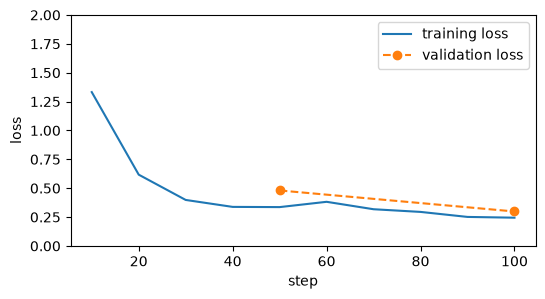

In [7]:
import matplotlib.pyplot as plt

ITERS, BATCH, LR = 100, 4, 5e-4

def loss_on(rows):
    """Mean cross-entropy on the reply tokens only, through layers 14-29 (with adapters) and the output layer."""
    L = max(len(i) for _, i, _ in rows)
    h = torch.zeros(len(rows), L, config.hidden_size); att = torch.zeros(len(rows), L, dtype=torch.long)
    for r, (hh, i, _) in enumerate(rows):
        h[r, :len(i)] = hh; att[r, :len(i)] = 1
    out = top(inputs_embeds=h, attention_mask=att, use_cache=False).last_hidden_state
    where = [(r, p) for r, (_, i, n) in enumerate(rows) for p in range(n - 1, len(i) - 1)]
    target = torch.tensor([rows[r][1][p + 1] for r, p in where])
    logits = tuned.base_model.model.lm_head(out[[r for r, _ in where], [p for _, p in where]])
    return torch.nn.functional.cross_entropy(logits, target), len(where)

@torch.no_grad()
def valid_loss():
    top.eval(); total = count = 0
    for k in range(0, len(valid_rows), BATCH):
        loss, n = loss_on(valid_rows[k:k + BATCH]); total += loss.item() * n; count += n
    return total / count

order = sorted(range(len(train_rows)), key=lambda i: len(train_rows[i][1]))   # similar lengths together
batches = [order[i:i + BATCH] for i in range(0, len(order) - BATCH + 1, BATCH)]
rng = np.random.default_rng(0)
optimizer = torch.optim.Adam([p for p in tuned.parameters() if p.requires_grad], lr=LR)

train_log, val_log = [], [(1, valid_loss())]
print(f"step   1  val {val_log[0][1]:.3f}")
step, recent, t0 = 0, [], time.time()
while step < ITERS:
    for b in rng.permutation(len(batches)):
        if step == ITERS: break
        top.train(); step += 1
        loss, _ = loss_on([train_rows[i] for i in batches[b]])
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        recent.append(loss.item())
        if step % 10 == 0:
            train_log.append((step, np.mean(recent))); recent = []
            print(f"step {step:3}  train {train_log[-1][1]:.3f}")
        if step % 50 == 0:
            val_log.append((step, valid_loss()))
            print(f"step {step:3}  val {val_log[-1][1]:.3f}")
print(f"{ITERS} steps in {time.time() - t0:.0f} s")
print(f"last report: train {train_log[-1][1]:.3f}  val {val_log[-1][1]:.3f}")

plt.figure(figsize=(6, 3))
plt.plot(*zip(*train_log), label="training loss")
plt.plot(*zip(*val_log[1:]), "o--", label="validation loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.ylim(0, 2); plt.legend(); plt.show()

## 8. After training: the held-out set

The same 40 messages through the tuned model, with only the instruction (no examples), as in the lesson.

**Look for:** **clean label 40**: every answer is one of the three team names. Our run got **right team 25**, more than
the prompted model's 19 but fewer than the lesson's 37. The cell lists every miss, so you can read them as you did on
screen 2: most misses send a Facilities or Events message to Billing.

In [8]:
t0 = time.time()
tuned_answers, right, clean = evaluate(tuned)
print(f"tuned, {len(HELD)} held-out messages: clean label {clean}, right team {right}   ({time.time() - t0:.0f} s)")
print("prompted (step 5): right team", sum(a == g for a, g in zip(prompted, gold)))
print("\nthe tuned model's misses:")
for (lang, team, text), a in zip(HELD, tuned_answers):
    if a != team:
        print(f"  {lang}  gold {team:10} tuned {a:10} {text}")

tuned, 40 held-out messages: clean label 40, right team 25   (104 s)
prompted (step 5): right team 19

the tuned model's misses:
  uz  gold Billing    tuned Events     Assalomu alaykum, fevral oyiga to'lovim o'tmabdi. Kartamda yetarli mablag' borligiga aminman. Tekshirib bera olmaysizmi?
  uz  gold Billing    tuned Events     Nega menga ikkinchi marta meetup uchun pul yechib olindi? Iltimos, buni tekshirib ko'ringlar.
  ko  gold Facilities tuned Billing    와이파이가 너무 느려서 업무를 할 수가 없어요. 도와주세요.
  ko  gold Facilities tuned Billing    환기가 안 되는지 방이 너무 더워요. 에어컨 좀 틀어주세요.
  ru  gold Facilities tuned Billing    Проектор в переговорке не работает. Нужно для презентации.
  uz  gold Facilities tuned Billing    Bugungi tadbirda proyektor ishlamadi. Bu juda xafa qildi.
  uz  gold Facilities tuned Events     Bu kunlarda zinadan ovoz ko'p chiqayapti, uni pasaytirish mumkinmi?
  ko  gold Facilities tuned Billing    오늘 행사장에서 마이크가 나오지 않았어요. 정말 큰일입니다.
  ko  gold Events     tuned Billing    워크숍 신청했는데, 취소하고 싶어

## 9. Did the fine-tune earn its keep? The paired comparison

`compare` is the lesson's function from `compare.py`, line for line. It counts the messages where only the tuned
model is right, where only the other one is right, and where they agree (both right or both wrong). Then it asks how
likely a split this lopsided would be if each disagreement were a fair coin toss (McNemar's test, exact form).

**Look for:** against the prompted model our run gives **10, 4, 26** and **p = 0.18**. The tuned model is ahead, but a
split of 10 to 4 happens about 18% of the time between equal systems, so this short run has not proven it better.
(The lesson's longer run split 20 to 2, p about 0.00012: decisive.) Against the recorded hosted model the tuned
model has **0** wins and 15 losses, p = 6.1e-05. Either way, the verdict for the README is the lesson's: the
fine-tune does not beat a prompted hosted model.

In [9]:
from math import comb

def compare(gold, prompted, tuned):
    only_tuned = only_prompted = agree = 0
    for g, p, t in zip(gold, prompted, tuned):
        if t == g and p != g:
            only_tuned += 1
        elif p == g and t != g:
            only_prompted += 1
        else:
            agree += 1
    flips = only_tuned + only_prompted
    k = min(only_tuned, only_prompted)
    p_value = min(1.0, 2 * sum(comb(flips, i) for i in range(k + 1)) / 2 ** flips)
    return only_tuned, only_prompted, agree, p_value

for name, other in [("prompted small model", prompted), ("hosted, prompt", HOSTED), ("hosted, prompt + rules", HOSTED_RULES)]:
    t, o, a, p = compare(gold, other, tuned_answers)
    print(f"tuned vs {name:22}: only tuned right {t:2} | only {name} right {o:2} | agree {a:2} | p = {p:.2g}")

tuned vs prompted small model  : only tuned right 10 | only prompted small model right  4 | agree 26 | p = 0.18
tuned vs hosted, prompt        : only tuned right  0 | only hosted, prompt right 15 | agree 25 | p = 6.1e-05
tuned vs hosted, prompt + rules: only tuned right  0 | only hosted, prompt + rules right 15 | agree 25 | p = 6.1e-05


## 10. Serve it behind FastAPI, and call it like a client

The lesson's `app.py` and `serve_check.py`, with the tuned model inside. `lifespan` loads the model **once**, before
the first request. In the notebook the model is already in memory, so "loading" means picking the tuned model and
switching the adapter on or off according to `ADAPTER_PATH`. `RouteIn` accepts a message of 1 to 1000 characters.
`RouteOut` lets only a real team name out, and the `if` turns any other answer into a 502. The prompt is built by
the same `chat_prompt` as the evaluation, and the answer by the same `reply`. The route is `async def`, as in the
lesson. (The lesson's MLX version crashed with a plain `def`; PyTorch has no such problem, so this notebook cannot
show that crash.)

FastAPI's `TestClient` sends real HTTP requests to the app inside this notebook and runs the `lifespan`.
`serve_check` checks the health endpoint, routes the Uzbek refund request, sends all 40 held-out messages through
HTTP and compares each team with the offline answers from step 8, and sends an empty message.

**Look for:** `200 {'team': 'Billing', 'adapter': 'adapters'}` for the refund request, status codes `{200: 40}`,
**same team as offline eval 40 of 40** (the service is the model you evaluated, even where that model is wrong), and
**422** for the empty message: FastAPI rejects it before the model is called. The milliseconds per request depend on
the machine (the lesson's Mac: median 106).

In [10]:
from contextlib import asynccontextmanager
from typing import Literal
from fastapi import FastAPI, HTTPException
from fastapi.testclient import TestClient
from pydantic import BaseModel, Field

ADAPTER_PATH = "adapters"   # the deployed setting; "" serves the untuned model
state = {}

@asynccontextmanager
async def lifespan(app):
    adapter = ADAPTER_PATH or None
    if adapter: tuned.base_model.enable_adapter_layers()
    else:       tuned.base_model.disable_adapter_layers()
    state["model"], state["adapter"] = tuned, adapter   # loaded once, before the first request
    yield
    tuned.base_model.enable_adapter_layers()
    state.clear()

app = FastAPI(lifespan=lifespan)

class RouteIn(BaseModel):
    message: str = Field(min_length=1, max_length=1000)

class RouteOut(BaseModel):
    team: Literal["Billing", "Facilities", "Events"]
    adapter: str | None

@app.post("/route", response_model=RouteOut)
async def route(body: RouteIn):
    answer = reply(state["model"], chat_prompt(body.message), max_tokens=8)
    if answer not in TEAMS:
        raise HTTPException(status_code=502, detail="model gave no team")
    return RouteOut(team=answer, adapter=state["adapter"])

@app.get("/health")
def health():
    return {"ready": "model" in state, "adapter": state.get("adapter")}

def serve_check():
    with TestClient(app) as client:
        r = client.get("/health"); print("GET /health", r.status_code, r.json())
        r = client.post("/route", json={"message": HELD[4][2]})
        print("POST /route", json.dumps({"message": HELD[4][2]}, ensure_ascii=False), "->", r.status_code, r.json())
        codes, same, ms = {}, 0, []
        for (_, _, text), off in zip(HELD, tuned_answers):
            t0 = time.perf_counter()
            r = client.post("/route", json={"message": text})
            ms.append((time.perf_counter() - t0) * 1000)
            codes[r.status_code] = codes.get(r.status_code, 0) + 1
            same += r.status_code == 200 and r.json()["team"] == off
        print("held-out through HTTP: status codes", codes, "| same team as offline eval", same, "of", len(HELD))
        print("ms per request: median", round(statistics.median(ms)), "slowest", round(max(ms)))
        r = client.post("/route", json={"message": ""})
        print('POST /route {"message": ""} ->', r.status_code, r.json()["detail"][0]["msg"])

serve_check()

GET /health 200 {'ready': True, 'adapter': 'adapters'}


POST /route {"message": "Men meetup uchun to'lagan edim, lekin kelolmadim. Pulni qaytarib olish imkoniyati bormi?"} -> 200 {'team': 'Billing', 'adapter': 'adapters'}


held-out through HTTP: status codes {200: 40} | same team as offline eval 40 of 40
ms per request: median 1278 slowest 2972
POST /route {"message": ""} -> 422 String should have at least 1 character


## 11. Broken on purpose: a deploy without the adapter

The lesson's second deploy forgot the adapter folder, so `ADAPTER_PATH` is empty and the untuned model is served.
Nothing crashes, and the health check still says ready.

**Look for:** `GET /health 200 {'ready': True, 'adapter': None}`: the health check already shows the problem. The
refund request gets **502** `model gave no team`, and all 40 held-out messages get 502 (status codes `{502: 40}`,
same team 0 of 40), because the untuned model never answers with a team name.

In [11]:
ADAPTER_PATH = ""   # the deploy that forgot the adapter folder
serve_check()
ADAPTER_PATH = "adapters"   # back to the deployed setting

GET /health 200 {'ready': True, 'adapter': None}


POST /route {"message": "Men meetup uchun to'lagan edim, lekin kelolmadim. Pulni qaytarib olish imkoniyati bormi?"} -> 502 {'detail': 'model gave no team'}


held-out through HTTP: status codes {502: 40} | same team as offline eval 0 of 40
ms per request: median 270 slowest 1245
POST /route {"message": ""} -> 422 String should have at least 1 character


## Now change it

Each cell below has one line marked `# <- change this`. Edit it, run the cell, and compare.

### Experiment 1: your own message through the endpoint

**What should change:** write any short message about a payment, the building or an event, in Uzbek, Russian or
Korean. The deployed service answers 200 with one team name. With `adapter = ""` the same message gets 502, because
the untuned model does not answer with a team name.

In [12]:
message = "Ertangi workshop soat nechada boshlanadi?"   # <- change this: any member message
adapter = "adapters"                                      # then try ""

ADAPTER_PATH = adapter
with TestClient(app) as client:
    r = client.post("/route", json={"message": message})
    print(r.status_code, r.json())
ADAPTER_PATH = "adapters"

200 {'team': 'Events', 'adapter': 'adapters'}


### Experiment 2: how many disagreements make a verdict?

The p-value in `compare` depends only on the two counts of disagreements. The cell computes it from counts you type.

**What should change:** our run's 10 to 4 gives p = 0.18, not decisive. The lesson's run on the Mac, 20 to 2, gives
about 0.00012. With 5 to 2 it rises to about 0.45. The same direction becomes a verdict only when there are enough
disagreements and the split is lopsided.

In [13]:
only_tuned, only_prompted = 10, 4   # <- change this: try 20, 2 (the lesson's run), then 5, 2

flips = only_tuned + only_prompted
k = min(only_tuned, only_prompted)
p_value = min(1.0, 2 * sum(comb(flips, i) for i in range(k + 1)) / 2 ** flips)
print(f"only tuned right {only_tuned} | only prompted right {only_prompted} | p = {p_value:.2g}")

only tuned right 10 | only prompted right 4 | p = 0.18


### Experiment 3: choose the opponent

The verdict depends on what you compare against. `other` is the second router in the comparison.

**What should change:** with `HOSTED`, the tuned model has 0 wins and 15 losses. With `base_answers` (the untuned
model, instruction only, step 4) the tuned model wins on every message it gets right (25 to 0) and the p-value is
tiny, because the base model gets none right. Beating your own untuned base is the easy test.

In [14]:
other = prompted   # <- change this: try HOSTED, then base_answers

t, o, a, p = compare(gold, other, tuned_answers)
print(f"only tuned right {t} | only the other right {o} | agree {a} | p = {p:.2g}")

only tuned right 10 | only the other right 4 | agree 26 | p = 0.18


## What you should see

- The untuned model with only the instruction answers 0 of 40 held-out messages with a team name (step 4).
- The prompted model (team descriptions and six examples) gets 19 of 40 right, the same as the lesson (step 5).
- At the last report the training loss is below the validation loss (0.245 against 0.298 in our run) (step 7).
- The tuned model routes 25 of 40 held-out messages to the gold team in our run, and every answer is one of the
  three team names (step 8).
- `compare` against the prompted model gives 10, 4, 26 and p = 0.18 in our run: ahead, but not proven. Against the
  hosted model the tuned model has 0 wins (step 9).
- Through the test client, `/route` gives the same team as the offline evaluation for 40 of 40 messages, and an empty
  message gets 422 (step 10).
- Without the adapter, the health check shows `'adapter': None` and every message gets 502 (step 11).

Your numbers can differ a little from ours on another CPU; the pattern should not. The router is your fine-tuning
portfolio project: keep the verdict, with the rejected option and why.